# Autoencoder vs. Week 4 on Recommendations

**Week 6 · Lesson 11** &nbsp;·&nbsp; GBUS 564: Predictive Analytics &nbsp;·&nbsp; Fall 2026

<a target="_blank" href="https://colab.research.google.com/github/avorybryant/umw_gbus564_fall26/blob/main/notebooks/week6/lectures/11_autoencoder_vs_week4_recommender.ipynb">
<img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>

*Adapted from D2L Ch. 21.4 (AutoRec: Rating Prediction with Autoencoders) and Sedhain
et al., "AutoRec: Autoencoders Meet Collaborative Filtering," WWW 2015.*

## Setup

Same boilerplate as every notebook this term — see Week 1 Lesson 8 if this is your
first time seeing it.

In [1]:
# Environment setup — identical across every notebook in the course.
# Installs the course package (dataset loaders + helpers) from the public
# course repo; Colab already has numpy/pandas/scikit-learn, so it's quick.
%pip install -q matplotlib git+https://github.com/avorybryant/umw_gbus564_fall26.git

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import set_config

set_config(display="diagram")
plt.rcParams["figure.figsize"] = (8, 5)

RANDOM_SEED = 564  # GBUS 564 — reuse this seed everywhere for reproducibility
rng = np.random.default_rng(RANDOM_SEED)

/home/avory/Desktop/repos/umw_predictive_analytics_fall26/.venv/bin/python: No module named pip


Note: you may need to restart the kernel to use updated packages.


## 1. Business Problem

**Business question:** Week 4 Lesson 8 shipped matrix factorization (ALS) to choose
the ten products each returning customer sees in a "you might also like" panel. Would
a neural network — Lesson 10's autoencoder — pick products customers are more likely
to actually buy next, enough to replace it?

**Why it matters:** every slot in that panel is a product the customer didn't see
instead, so better picks are more sales from the same screen space. But ALS is already
built, trains in seconds, and Week 4 tuned it on this exact data. A challenger has to
beat it on the same customers' real later purchases, not on a promise.

**Why an autoencoder is a fair challenger.** Week 4's matrix factorization compressed
each customer's purchase row to a short vector — "one k-dim taste vector per
customer" — and scored every product from it. An autoencoder does the same job with
a network: its encoder squeezes the purchase row through a narrow **bottleneck**, and
its decoder rebuilds the full row, scoring every product along the way. The bottleneck
is the customer's embedding, the network's version of ALS's latent factors (Lesson 10).
In fact, strip the activation functions out and train on squared error, and an
autoencoder learns the same subspace as Week 4's truncated SVD — so this notebook
asks one precise question: **does the nonlinearity Lessons 2–7 built up actually buy
better recommendations?**

As in Lesson 9, Lesson 8's rule applies in both directions — don't dismiss the
network because simple models usually win on tables, and don't adopt it because it's
newer. Check it.

## 2. Data

*Load, describe, and sanity-check the data before touching a model.*

Same **Online Retail** dataset as Week 4 Lesson 8 (`load_online_retail()` in
`gbus564_coursework.utils.course_data`): one row per invoice line from a UK online
gift retailer, December 2010 – December 2011, already cleaned of cancellations and
lines with no customer ID.

In [2]:
from gbus564_coursework.utils.course_data import load_online_retail

df = load_online_retail()
print(f"{len(df):,} invoice lines · {df['CustomerID'].nunique():,} customers · "
      f"{df['StockCode'].nunique():,} products")
print(f"date range: {df['InvoiceDate'].min().date()} to {df['InvoiceDate'].max().date()}")
df.head()

397,884 invoice lines · 4,338 customers · 3,665 products
date range: 2010-12-01 to 2011-12-09


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


### Data Prep

**Week 4's matrix and split, unchanged.** Every customer-product pair becomes one cell
of a binary customer × product matrix (bought it at all = 1). The split is Week 4's
two shared calendar cutoffs: purchases before **20 Sep 2011** train, 20 Sep – 31 Oct
is the validation window for choosing settings, and **1 Nov 2011 onward** is the test
— what each customer actually went on to buy. A hit is Week 4's definition too: a
product new to a customer who already has history (re-orders are a separate job, and
customers with no history are cold-start, not scored).

The code below is copied from Week 4 Lesson 8 so every model in this notebook is
judged on exactly the customers and purchases Week 4's were. There's nothing to scale
or encode — the matrix is already 0s and 1s — so the define-in-Data, fit-in-Model
rule has nothing to define here.

In [3]:
from scipy.sparse import coo_matrix, csr_matrix

# Give every customer and product an integer index: the row/column it owns in the matrix
customer_cat = df["CustomerID"].astype("category")
item_cat = df["StockCode"].astype("category")
customers = customer_cat.cat.categories  # row index -> CustomerID
items = item_cat.cat.categories          # column index -> StockCode
item_names = df.drop_duplicates("StockCode").set_index("StockCode")["Description"]

row = customer_cat.cat.codes.to_numpy()
col = item_cat.cat.codes.to_numpy()
n_customers, n_items = len(customers), len(items)


def bought(X, u):
    """The products customer u has a purchase of in matrix X (column indices)."""
    return X.indices[X.indptr[u]:X.indptr[u + 1]]


def product_name(i):
    return item_names.get(items[i], "?")


# Two calendar cutoffs, shared by every customer (Week 4 Lesson 8)
VAL_START, TEST_START = pd.Timestamp("2011-09-20"), pd.Timestamp("2011-11-01")

buys = pd.DataFrame({"u": row, "i": col, "date": df["InvoiceDate"].to_numpy()})
is_train = buys["date"] < VAL_START
is_val = buys["date"].between(VAL_START, TEST_START, inclusive="left")
is_test = buys["date"] >= TEST_START


def to_matrix(cells):
    cells = cells.drop_duplicates(["u", "i"])  # purchased at all, regardless of how many times
    return csr_matrix((np.ones(len(cells)), (cells["u"], cells["i"])), shape=(n_customers, n_items))


train = to_matrix(buys[is_train])               # for choosing settings
train_val = to_matrix(buys[is_train | is_val])  # for the final fit


def new_products(window, seen):
    """For each customer with earlier history, the products they bought in
    this window but never before it."""
    hits = {}
    for u, products in window.groupby("u")["i"]:
        before = set(bought(seen, u))
        if not before:
            continue                           # no history = cold-start, not scored
        new = set(products) - before           # never bought before = discovery
        if new:
            hits[u] = new
    return hits


val_sets = new_products(buys[is_val], seen=train)
test_sets = new_products(buys[is_test], seen=train_val)
eval_users = np.array(sorted(test_sets))

print(f"matrix: {n_customers:,} customers x {n_items:,} products, "
      f"{train_val.nnz / (n_customers * n_items):.2%} filled")
print(f"purchase lines: train {is_train.mean():.1%}, validation {is_val.mean():.1%}, test {is_test.mean():.1%}")
print(f"{len(val_sets):,} customers scored on validation, {len(eval_users):,} on test")

matrix: 4,338 customers x 3,665 products, 1.39% filled
purchase lines: train 62.4%, validation 17.0%, test 20.6%
1,220 customers scored on validation, 1,453 on test


## 3. Model

*Baseline first — the reference every model must beat — then the model
under study.*

**The bar: Week 4's models, refit with Week 4's settings.** Lessons 7 and 9 quoted
Week 5's scores rather than refitting, but this notebook needs each customer's own
score under every model for the paired comparison in Section 4, so Week 4's four
methods are refit here — same split, and the settings Week 4 chose on this exact
validation window (SVD with k = 30, ALS with k = 60). Nothing is re-tuned.

In [4]:
%pip install -q implicit keras
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics.pairwise import cosine_similarity
from implicit.als import AlternatingLeastSquares
from threadpoolctl import threadpool_limits

threadpool_limits(1, "blas")  # implicit runs its own threads; avoid oversubscribing


def top_n(scores, X, u, n=10):
    """The n highest-scoring products customer u hasn't already bought in X."""
    scores = scores.copy()
    scores[bought(X, u)] = -np.inf  # never recommend something already bought
    top = np.argpartition(-scores, n)[:n]
    return top[np.argsort(-scores[top])].tolist()


# Popularity (baseline): the best-sellers each customer hasn't bought
item_popularity = np.asarray(train_val.sum(axis=0)).ravel().astype(float)
recommend_popularity = lambda u, n=10: top_n(item_popularity, train_val, u, n)

# Item-based CF: products similar to what the customer already bought
item_sim = cosine_similarity(train_val.T)
recommend_item_cf = lambda u, n=10: top_n(item_sim[bought(train_val, u)].sum(axis=0), train_val, u, n)

# Matrix factorization — truncated SVD, k = 30
svd = TruncatedSVD(n_components=30, random_state=RANDOM_SEED)
svd_scores = svd.fit_transform(train_val) @ svd.components_
recommend_svd = lambda u, n=10: top_n(svd_scores[u], train_val, u, n)

# Matrix factorization — ALS, k = 60 (Week 4's choice for the panel)
als = AlternatingLeastSquares(factors=60, regularization=10.0, alpha=1.0,
                              iterations=20, random_state=RANDOM_SEED)
als.fit(train_val, show_progress=False)
als_scores = np.asarray(als.user_factors) @ np.asarray(als.item_factors).T
recommend_als = lambda u, n=10: top_n(als_scores[u], train_val, u, n)

/home/avory/Desktop/repos/umw_predictive_analytics_fall26/.venv/bin/python: No module named pip


Note: you may need to restart the kernel to use updated packages.


**The challenger: an autoencoder on purchase rows.** Each customer's row of the matrix
— 3,665 zeros and ones — goes in, and the network is trained to rebuild that same row
at the output. Everything is Lessons 2–7:

- **Dropout on the input (20%)** — Lesson 6's regularizer, used here with a second
  purpose: training hides a random fifth of each customer's purchases and asks the
  network to put them back. That's the recommendation task in miniature — *given what
  they bought, what else belongs in this basket?*
- **A 128-unit ReLU bottleneck** — the customer's embedding. Narrower than the input,
  so the network can't just copy the row through; it has to learn which products go
  together.
- **3,665 sigmoid outputs, binary cross-entropy** — one "would they have this?"
  probability per product, Lesson 4's pairing for a 0/1 target. Lesson 6's L2 weight
  decay on both layers.

After training, the rebuilt row scores every product — including ones the customer
never bought, which are exactly the recommendations. The settings (bottleneck 128,
dropout 0.2) and the loss are checked in Model Selection below.

In [5]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"  # CPU only: hide any NVIDIA GPU (must run before keras loads)
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"   # quiet TensorFlow's startup info/warning/error logs

import tensorflow as tf
tf.config.set_visible_devices([], "GPU")    # also hides Apple-silicon (Metal) GPUs; restart the kernel to re-run

import keras
from keras import layers


def weighted_bce(alpha):
    """Binary cross-entropy where a purchase counts 1 + alpha times as much as a blank:
    the same confidence weighting as Week 4's ALS (its `alpha` argument)."""
    def loss(y_true, y_pred):
        p = keras.ops.clip(y_pred, 1e-7, 1 - 1e-7)
        bce = -(y_true * keras.ops.log(p) + (1 - y_true) * keras.ops.log(1 - p))
        return keras.ops.mean((1 + alpha * y_true) * bce, axis=-1)
    return loss


def build_autoencoder(n_products, bottleneck=128, dropout=0.2, l2=1e-5, alpha=0.0):
    """alpha = 0 is plain binary cross-entropy: every blank counts as much as a purchase."""
    keras.utils.set_random_seed(RANDOM_SEED)
    penalty = keras.regularizers.l2(l2)
    model = keras.Sequential([
        keras.Input(shape=(n_products,)),
        layers.Dropout(dropout, name="hide_purchases"),  # hide some purchases; learn to put them back
        layers.Dense(bottleneck, activation="relu", kernel_regularizer=penalty, name="bottleneck"),
        layers.Dense(n_products, activation="sigmoid", kernel_regularizer=penalty, name="rebuilt_row"),
    ])
    model.compile(optimizer="adam", loss="binary_crossentropy" if alpha == 0 else weighted_bce(alpha))
    return model


build_autoencoder(n_items).summary()

I0000 00:00:1794786210.796849   74686 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794786210.797192   74686 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794786210.823296   74686 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI AVX_VNNI_INT8 AVX_NE_CONVERT FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1794786211.360860   74686 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794786211.361041   74686 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
E0000 00:00:1794786211.426416   74686 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hide_purchases (Dropout)        │ (None, 3665)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bottleneck (Dense)              │ (None, 128)            │       469,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rebuilt_row (Dense)             │ (None, 3665)           │       472,785 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 942,033 (3.59 MB)

 Trainable params: 942,033 (3.59 MB)

 Non-trainable params: 0 (0.00 B)

### Model Selection

**How long to train — early stopping on the business metric.** Lesson 7 stopped
training when validation *loss* turned up. Here the loss is a poor guide — it rewards
rebuilding purchases the customer already made, which the panel never shows — so
training is checked against what the panel is for: validation NDCG@10 on new products
customers bought in the validation window. The network trains on the pre-September
matrix in 10-epoch rounds, and the round where validation NDCG@10 peaks sets the
epoch count for the final fit. *(The slowest cell in the notebook — a couple of minutes on a CPU.)*

10     0.0613
20     0.0759
30     0.0844
40     0.0875
50     0.0897
60     0.0906
70     0.0910
80     0.0915
90     0.0906
100    0.0913
110    0.0906
120    0.0903


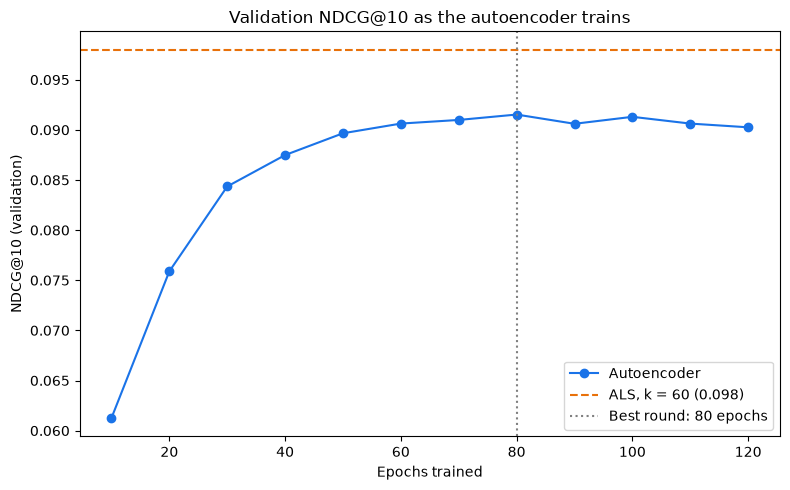

In [6]:
def ndcg_at_k(recommended, relevant, k):
    """Week 4 Lesson 8's NDCG@k: hits near the top of the list count more."""
    dcg = sum(1 / np.log2(i + 2) for i, item in enumerate(recommended[:k]) if item in relevant)
    idcg = sum(1 / np.log2(i + 2) for i in range(min(len(relevant), k)))
    return dcg / idcg if idcg > 0 else 0.0


X_train = train.toarray().astype("float32")
autoencoder = build_autoencoder(n_items)
curve = {}
for epoch in range(10, 121, 10):
    autoencoder.fit(X_train, X_train, epochs=10, batch_size=64, verbose=0)
    scores = autoencoder.predict(X_train, batch_size=512, verbose=0)
    curve[epoch] = np.mean([ndcg_at_k(top_n(scores[u], train, u), val_sets[u], 10) for u in val_sets])
curve = pd.Series(curve, name="validation NDCG@10")
best_epochs = int(curve.idxmax())

# ALS on the same validation window, for reference
als_check = AlternatingLeastSquares(factors=60, regularization=10.0, alpha=1.0,
                                    iterations=20, random_state=RANDOM_SEED)
als_check.fit(train, show_progress=False)
als_check_scores = np.asarray(als_check.user_factors) @ np.asarray(als_check.item_factors).T
als_val = np.mean([ndcg_at_k(top_n(als_check_scores[u], train, u), val_sets[u], 10) for u in val_sets])

curve.plot(marker="o", color="#1A73E8", label="Autoencoder")
plt.axhline(als_val, color="#E8710A", ls="--", label=f"ALS, k = 60 ({als_val:.3f})")
plt.axvline(best_epochs, color="gray", ls=":", label=f"Best round: {best_epochs} epochs")
plt.title("Validation NDCG@10 as the autoencoder trains")
plt.xlabel("Epochs trained")
plt.ylabel("NDCG@10 (validation)")
plt.legend()
plt.tight_layout()
print(curve.round(4).to_string())

**Reading the curve.** Validation NDCG@10 climbs fast for the first 50 epochs,
peaks at **0.092 after 80**, then drifts down — Lesson 6's overfitting shape, measured
in recommendation quality instead of loss: past 80 epochs the network starts
memorizing pre-September baskets instead of learning what goes with what. Even at its
peak it sits below ALS on the same window (0.098). That's the first hint of the
answer, but validation chose the settings, so the test set has the final word.

**Did the settings and the loss matter?** Two choices above went untested: the
network's size (bottleneck 128, dropout 0.2), and *how blanks count* in the loss. Week 4
found the second one decisive — ALS beat SVD by weighting each purchase more than a blank
(its `alpha`) instead of reading every blank as a dislike. `build_autoencoder` takes the
same `alpha`, so the cell below tries both: a grid of bottleneck × dropout with the plain
loss, then the plain loss against purchase weights of 5, 20, and 50. Every candidate gets
the training curve above and is scored on the same validation window.

The full sweep is nine networks — about 20 minutes on a CPU — so by default the cell shows
the results recorded from running it. Set `RUN_SWEEP = True` to rerun it yourself.

In [7]:
RUN_SWEEP = False  # True reruns all nine networks (~20 min on a CPU)


def best_round(bottleneck=128, dropout=0.2, alpha=0.0, max_epochs=120):
    """Train in 10-epoch rounds; return (best epochs, best validation NDCG@10)."""
    model = build_autoencoder(n_items, bottleneck, dropout, alpha=alpha)
    scores_by_round = {}
    for epoch in range(10, max_epochs + 1, 10):
        model.fit(X_train, X_train, epochs=10, batch_size=64, verbose=0)
        scores = model.predict(X_train, batch_size=512, verbose=0)
        scores_by_round[epoch] = np.mean([ndcg_at_k(top_n(scores[u], train, u), val_sets[u], 10)
                                          for u in val_sets])
    best = max(scores_by_round, key=scores_by_round.get)
    return best, scores_by_round[best]


# 1) Network size: every bottleneck × dropout pair, plain loss (alpha = 0) → 6 networks
size_runs = [("settings", bottleneck, dropout, 0.0)
             for bottleneck in (64, 128, 256)
             for dropout in (0.2, 0.5)]

# 2) How blanks count: purchase weights at the default size (128, 0.2) → 3 networks
#    (alpha = 0 at that size is already in the grid above)
loss_runs = [("loss", 128, 0.2, alpha) for alpha in (5.0, 20.0, 50.0)]

candidates = size_runs + loss_runs
if RUN_SWEEP:
    rows = [(kind, b, d, a, *best_round(b, d, a)) for kind, b, d, a in candidates]
else:
    # Recorded from RUN_SWEEP = True (same data, split, and seed); validation NDCG@10
    recorded = {(64, 0.2, 0.0): (120, 0.0897), (64, 0.5, 0.0): (110, 0.0886),
                (128, 0.2, 0.0): (80, 0.0915), (128, 0.5, 0.0): (80, 0.0894),
                (256, 0.2, 0.0): (50, 0.0905), (256, 0.5, 0.0): (110, 0.0876),
                (128, 0.2, 5.0): (60, 0.0882), (128, 0.2, 20.0): (30, 0.0840),
                (128, 0.2, 50.0): (30, 0.0840)}
    rows = [(kind, b, d, a, *recorded[(b, d, a)]) for kind, b, d, a in candidates]

sweep = pd.DataFrame(rows, columns=["check", "bottleneck", "dropout", "alpha",
                                    "best epochs", "validation NDCG@10"])
print("Network size (plain loss, alpha = 0):")
print(sweep[sweep["check"] == "settings"]
      .pivot(index="bottleneck", columns="dropout", values="validation NDCG@10").round(4).to_string())
print("\nHow blanks count (bottleneck 128, dropout 0.2):")
loss_check = pd.concat([sweep[(sweep["bottleneck"] == 128) & (sweep["dropout"] == 0.2)
                              & (sweep["alpha"] == 0)], sweep[sweep["check"] == "loss"]])
print(loss_check[["alpha", "best epochs", "validation NDCG@10"]].round(4).to_string(index=False))
print(f"\nALS on the same window: {als_val:.4f}")

Network size (plain loss, alpha = 0):
dropout        0.2     0.5
bottleneck                
64          0.0897  0.0886
128         0.0915  0.0894
256         0.0905  0.0876

How blanks count (bottleneck 128, dropout 0.2):
 alpha  best epochs  validation NDCG@10
   0.0           80              0.0915
   5.0           60              0.0882
  20.0           30              0.0840
  50.0           30              0.0840

ALS on the same window: 0.0980


**Reading the checks.** The network's size barely matters: all six combinations land
between 0.088 and 0.092, and the settings used here (128, 0.2) are the best of them. The
loss result is the more interesting one. Weighting purchases the way ALS does made the
network *worse* — 0.0882 at α = 5, down to 0.084 at α = 20 and 50 — and the weighted
networks peaked earlier (30–60 epochs), a sign they overfit faster. A likely reason: the
20% input dropout already trains the network on uncertain blanks, by hiding real
purchases and asking for them back, so weighting purchases on top of that overcorrects.
The design choice that decided Week 4 didn't carry over to a different model, and that's
worth checking rather than assuming. None of these candidates reaches ALS (0.098) on this
window, so the plain-loss network from the curve above goes forward unchanged.

In [8]:
# Final fit: retrain from scratch on everything before the test window, for the chosen epochs
X_train_val = train_val.toarray().astype("float32")
autoencoder = build_autoencoder(n_items)
autoencoder.fit(X_train_val, X_train_val, epochs=best_epochs, batch_size=64, verbose=0)

ae_scores = autoencoder.predict(X_train_val, batch_size=512, verbose=0)
recommend_autoencoder = lambda u, n=10: top_n(ae_scores[u], train_val, u, n)

## 4. Evaluate

*Score against the baseline, not in isolation — a metric only means
something next to what it's beating.*

Week 4's three metrics on every returning customer's test-window purchases: of the
ten products shown, how many were bought (**precision@10**), how many of the
customer's new purchases the list caught (**recall@10**), and **NDCG@10**, which also
rewards putting the hits near the top. NDCG@10 is the headline, as in Week 4.

In [9]:
def precision_at_k(recommended, relevant, k):
    return len(set(recommended[:k]) & relevant) / k


def recall_at_k(recommended, relevant, k):
    return len(set(recommended[:k]) & relevant) / len(relevant) if relevant else 0.0


K = 10
methods = {
    "Popularity (baseline)": recommend_popularity,
    "Item-based CF": recommend_item_cf,
    "Matrix factorization — truncated SVD": recommend_svd,
    "Matrix factorization — ALS": recommend_als,
    "Autoencoder": recommend_autoencoder,
}

rows = []
for name, recommend in methods.items():
    for u in eval_users:
        relevant, recommended = test_sets[u], recommend(u, K)
        rows.append({
            "method": name, "customer": u,
            "precision@10": precision_at_k(recommended, relevant, K),
            "recall@10": recall_at_k(recommended, relevant, K),
            "ndcg@10": ndcg_at_k(recommended, relevant, K),
        })
per_customer = pd.DataFrame(rows)

results = per_customer.groupby("method", sort=False)[["precision@10", "recall@10", "ndcg@10"]].mean()
results.round(3)

,precision@10,recall@10,ndcg@10
method,,,
Popularity (baseline),0.034,0.019,0.037
Item-based CF,0.058,0.044,0.072
Matrix factorization — truncated SVD,0.078,0.053,0.095
Matrix factorization — ALS,0.081,0.059,0.102
Autoencoder,0.081,0.055,0.100


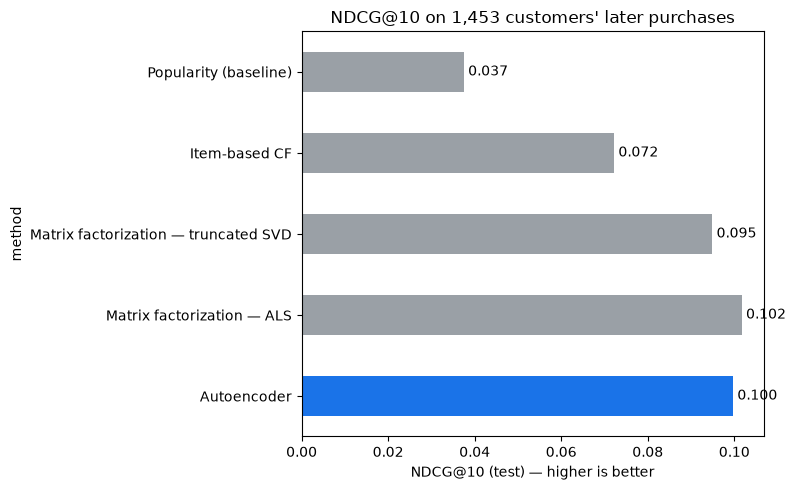

In [10]:
colors = ["#9AA0A6"] * 4 + ["#1A73E8"]
results["ndcg@10"].plot.barh(color=colors,
                             title=f"NDCG@10 on {len(eval_users):,} customers' later purchases")
plt.gca().invert_yaxis()
plt.xlabel("NDCG@10 (test) — higher is better")
for i, v in enumerate(results["ndcg@10"]):
    plt.text(v + 0.001, i, f"{v:.3f}", va="center")
plt.tight_layout()

**Reading the scoreboard.** The autoencoder lands at **0.100 NDCG@10** — well clear
of popularity (0.037) and item-based CF (0.072), ahead of truncated SVD (0.095), and
just behind ALS (0.102). Precision@10 is a dead heat at 0.081: on average, about 0.8 of the ten products
either model shows go on to be bought.

The SVD row is the one to read closely. SVD is the autoencoder with the
nonlinearity removed, so the 0.095 → 0.100 step is what Lessons 2–7's hidden-layer
machinery bought on this task. ALS gets the same distance and slightly more without
it — by weighting what each customer *did* buy more heavily than the blanks, a choice
Week 4 tuned on this data.

**Is the gap real?** Every method was scored on the same 1,453 customers, so the fair
comparison is *paired*: resample customers 1,000 times, and each time take the
average difference in NDCG@10 between two methods on the customers drawn. If the
middle 95% of those differences straddles zero, this test set can't tell the two
apart.

In [11]:
ndcg = per_customer.pivot(index="customer", columns="method", values="ndcg@10")


def paired_bootstrap(a, b, n_boot=1000):
    """95% interval for mean(a - b) over customers, resampling customers."""
    diff = (ndcg[a] - ndcg[b]).to_numpy()
    draws = rng.integers(0, len(diff), size=(n_boot, len(diff)))
    return np.percentile(diff[draws].mean(axis=1), [2.5, 97.5])


for rival in ["Matrix factorization — ALS", "Matrix factorization — truncated SVD"]:
    low, high = paired_bootstrap("Autoencoder", rival)
    gap = ndcg["Autoencoder"].mean() - ndcg[rival].mean()
    print(f"Autoencoder − {rival.split('— ')[1]}: {gap:+.4f} NDCG@10  (95% interval {low:+.4f} to {high:+.4f})")

Autoencoder − ALS: -0.0020 NDCG@10  (95% interval -0.0065 to +0.0024)
Autoencoder − truncated SVD: +0.0048 NDCG@10  (95% interval +0.0004 to +0.0097)


**Reading the intervals.** Against **ALS**, the autoencoder's −0.0020 has an interval
from −0.0065 to +0.0024 — it straddles zero, so on this test set the two are a **tie**.
Against **SVD**, the +0.0048 interval (+0.0004 to +0.0097) sits above zero, if only
just: the nonlinearity's gain over the linear version is small, and real on this test
set, though a different split could plausibly blur it. So the network
earned a place on the scoreboard — and drew with the model already in production.

## 5. Interpret

*What is the model actually keying off of? Business-readable, not just
statistically significant.*

**Who does each model serve better?** Week 4 split customers by how many products
they'd bought before the test window and found ALS led in every segment. Same split,
with the autoencoder added:

In [12]:
history = pd.Series({u: len(bought(train_val, u)) for u in eval_users})
per_customer["products bought before"] = pd.cut(
    per_customer["customer"].map(history), [0, 5, 10, 20, 50, 100, history.max()]
)
by_history = per_customer.pivot_table(
    index="products bought before", columns="method", values="ndcg@10", observed=True
)[["Matrix factorization — truncated SVD", "Matrix factorization — ALS", "Autoencoder"]]
by_history.columns = ["SVD", "ALS", "Autoencoder"]
by_history["customers"] = per_customer.groupby("products bought before", observed=True)["customer"].nunique()
by_history.round(3)

,SVD,ALS,Autoencoder,customers
products bought before,,,,
"(0, 5]",0.082,0.110,0.078,42
"(5, 10]",0.089,0.091,0.088,65
"(10, 20]",0.093,0.096,0.097,159
"(20, 50]",0.098,0.105,0.098,386
"(50, 100]",0.077,0.081,0.085,394
"(100, 1615]",0.112,0.122,0.121,407


**Reading the segments.** No segment flips the verdict. The autoencoder edges ALS for
customers with 50–100 past products (0.085 vs. 0.081) and matches it for the heaviest
buyers, but trails badly for the 42 customers with five or fewer (0.078 vs. 0.110) —
with so little in the row, there's little for the network to rebuild from, while
ALS's weighting of observed purchases makes the most of each one. Small segments are
noisy, so read this as "no customer group where the network clearly wins," not as a
new finding about light buyers.

**One customer, two panels.** Week 4's demo customer (ID 16164, hand-picked there
for a clear vintage-Christmas theme) — what each model would put in the panel, with
✓ on products they went on to buy:

In [13]:
demo_u = customers.get_loc(16164)
truth = test_sets[demo_u]


def show(i):
    return product_name(i) + (" ✓" if i in truth else "")  # ✓ = they went on to buy it


print("Already bought:", [product_name(i) for i in bought(train_val, demo_u)][:12], "...")
print()
print("ALS recommends:        ", [show(i) for i in recommend_als(demo_u, 5)])
print()
print("Autoencoder recommends:", [show(i) for i in recommend_autoencoder(demo_u, 5)])

Already bought: ['PACK OF 6 SWEETIE GIFT BOXES', 'PACK OF 6 PANNETONE GIFT BOXES', 'RIBBON REEL SNOWY VILLAGE', 'SET OF 20 VINTAGE CHRISTMAS NAPKINS', 'PAPER CHAIN KIT VINTAGE CHRISTMAS', '36 DOILIES VINTAGE CHRISTMAS', 'LED TEA LIGHTS', 'CHRISTMAS TABLE CANDLE SILVER SPIKE', 'BOX OF 6 MINI VINTAGE CRACKERS', 'ROLL WRAP VINTAGE CHRISTMAS', 'ROLL WRAP VINTAGE SPOT ', '6 GIFT TAGS VINTAGE CHRISTMAS '] ...

ALS recommends:         ["PAPER CHAIN KIT 50'S CHRISTMAS  ✓", '60 CAKE CASES VINTAGE CHRISTMAS', "BOX OF 6 MINI 50'S CRACKERS", 'SET OF 6 RIBBONS VINTAGE CHRISTMAS ✓', 'BISCUIT TIN VINTAGE CHRISTMAS ✓']

Autoencoder recommends: ["PAPER CHAIN KIT 50'S CHRISTMAS  ✓", '60 CAKE CASES VINTAGE CHRISTMAS', 'SET OF 6 RIBBONS VINTAGE CHRISTMAS ✓', "BOX OF 6 MINI 50'S CRACKERS", 'VINTAGE CHRISTMAS STOCKING ']


**Reading the panels.** The two models largely agree — both stay inside the
customer's vintage-Christmas theme, and four of the five products overlap. ALS's list
catches three products they went on to buy; the autoencoder's catches two, swapping
the biscuit tin for a stocking. One customer proves nothing either way, but it makes
the scoreboard concrete: these are two routes to nearly the same panel.

**The bottleneck as a second product: customers it can't rebuild.** Lesson 10 named
two uses for an autoencoder's bottleneck — an embedding, and an anomaly score. The
same trained network gives the second one for free: for each customer, the average
probability it assigns to the products they *actually* bought. A high score means
their basket looks like baskets the network has seen; a low score means it couldn't
rebuild what they bought — an unusual customer.

In [14]:
rebuild = pd.Series({u: ae_scores[u, bought(train_val, u)].mean()
                     for u in range(n_customers) if len(bought(train_val, u)) >= 5},
                    name="rebuild score")
print(f"{len(rebuild):,} customers with 5+ products; median rebuild score {rebuild.median():.2f}")
print()
for u in rebuild.nsmallest(3).index:
    basket = [product_name(i) for i in bought(train_val, u)]
    print(f"Customer {customers[u]} — rebuild score {rebuild[u]:.3f}, {len(basket)} products:")
    print("   ", basket[:6], "..." if len(basket) > 6 else "")

3,736 customers with 5+ products; median rebuild score 0.10

Customer 15512 — rebuild score 0.004, 7 products:
    ['ANTIQUE GLASS HEART DECORATION ', 'WHITE HONEYCOMB PAPER GARLAND ', 'GLITTER HEART GARLAND WITH BELLS ', 'SET OF 3 BIRD LIGHT PINK FEATHER ', 'PINK CHRISTMAS FLOCK DROPLET ', 'ACRYLIC JEWEL SNOWFLAKE,PINK'] ...
Customer 13218 — rebuild score 0.006, 5 products:
    ['PARTY TIME PENCIL ERASERS', 'BASKET OF TOADSTOOLS', 'PACK OF 12 WOODLAND TISSUES ', 'PACK 6 HEART/ICE-CREAM PATCHES', 'S/4 PINK FLOWER CANDLES IN BOWL'] 
Customer 18101 — rebuild score 0.006, 13 products:
    ['MIRROR MOSAIC VOTIVE HOLDER', 'FIVE HEART HANGING DECORATION', 'EDWARDIAN PHOTO FRAME', 'EDWARDIAN HEART PHOTO FRAME', 'VINTAGE BEAD PINK PURSE ', 'VINTAGE BEAD NOTEBOOK'] ...


**Reading the outliers.** The median customer's purchases get a rebuild probability of
about 0.10; these three get under 0.01. They aren't fraud or errors — they're
customers whose combinations don't match anyone else's, like a basket of pink
feather birds, honeycomb garlands, and jewel snowflakes. For the recommendation panel
that's a warning: any crowd-based recommender, ALS included, has the least to go on
for customers like these, because there's no crowd like them to learn from. Used on its own, the same score is a cheap
unusual-customer flag that needs no labels — but the threshold, and what anyone does
with a flagged customer, is a business choice this notebook doesn't make.

## 6. Recommend

**Recommendation:** keep **ALS** in the "you might also like" panel. The autoencoder
tied it on what customers actually bought next (NDCG@10 0.100 vs. 0.102, a gap this
test set can't distinguish from zero), and a tie goes to the model that's already
running, trains in seconds instead of minutes, and has one less framework to maintain.
Lesson 8's rule — prefer the simpler model on a tie — decides it, just as it did for
TabPFN in Lesson 9.

**What the network did prove:** the nonlinearity is worth something here — it beat
its own linear version, Week 4's SVD, by a margin the bootstrap says is real, if small. That's
the honest shape of deep learning on business tables: competitive, sometimes better
than a naive baseline, rarely better than the tuned simple model.

**Caveats / next steps:**
- **Where the network would earn its place** — inputs ALS can't take. An autoencoder
  can be fed product descriptions, prices, or a customer's purchase *order* alongside
  the basket; ALS only sees the 0/1 matrix. That's where neural recommenders pull
  ahead in practice, and it's worth retesting if those features become available.
- **Re-orders are still unserved** — Week 4 found about 40% of returning customers'
  test purchases were re-buys, which neither model is scored on. That remains a
  separate, probably simpler, job.
- **The rebuild score** is a free by-product worth handing to merchandising as an
  unusual-customer list — but as a lead to look at, not a flag to act on
  automatically.